In [1]:
import pandas as pd 

df = pd.read_csv("hr_employee_data.csv", sep=";")

print(df.head())
print(df.shape)

     Emp_Id satisfaction_level last_evaluation  number_project  \
0  IND02438                38%             53%               2   
1  IND28133                80%             86%               5   
2  IND07164                11%             88%               7   
3  IND30478                72%             87%               5   
4  IND24003                37%             52%               2   

   average_montly_hours  time_spend_company  Work_accident  left  \
0                   157                   3              0     1   
1                   262                   6              0     1   
2                   272                   4              0     1   
3                   223                   5              0     1   
4                   159                   3              0     1   

   promotion_last_5years Department  salary  
0                      0      sales     low  
1                      0      sales  medium  
2                      0      sales  medium  
3         

In [2]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Emp_Id                 14999 non-null  str  
 1   satisfaction_level     14999 non-null  str  
 2   last_evaluation        14999 non-null  str  
 3   number_project         14999 non-null  int64
 4   average_montly_hours   14999 non-null  int64
 5   time_spend_company     14999 non-null  int64
 6   Work_accident          14999 non-null  int64
 7   left                   14999 non-null  int64
 8   promotion_last_5years  14999 non-null  int64
 9   Department             14999 non-null  str  
 10  salary                 14999 non-null  str  
dtypes: int64(6), str(5)
memory usage: 1.6 MB
None
Emp_Id                   0
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left        

In [3]:
print(df[['satisfaction_level', 'last_evaluation']].head())

  satisfaction_level last_evaluation
0                38%             53%
1                80%             86%
2                11%             88%
3                72%             87%
4                37%             52%


In [4]:
df['last_evaluation'] = df ['last_evaluation'].str.replace('%', '').astype(float) / 100

df.head()

,Emp_Id,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,IND02438,38%,0.53,2,157,3,0,1,0,sales,low
1,IND28133,80%,0.86,5,262,6,0,1,0,sales,medium
2,IND07164,11%,0.88,7,272,4,0,1,0,sales,medium
3,IND30478,72%,0.87,5,223,5,0,1,0,sales,low
4,IND24003,37%,0.52,2,159,3,0,1,0,sales,low


In [5]:

print(df.columns)

Index(['Emp_Id', 'satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='str')


In [6]:
df = df.drop('Emp_Id', axis=1)

In [7]:
print(df.columns)

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='str')


In [8]:
print(df['left'].value_counts())

left
0    11428
1     3571
Name: count, dtype: int64


In [9]:
df = pd.get_dummies(df, columns=['Department', 'salary'], dtype=int)
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department_IT,Department_RandD,...,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical,salary_high,salary_low,salary_medium
0,38%,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,80%,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,11%,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,72%,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,37%,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0


In [10]:
print(df.dtypes)

satisfaction_level            str
last_evaluation           float64
number_project              int64
average_montly_hours        int64
time_spend_company          int64
Work_accident               int64
left                        int64
promotion_last_5years       int64
Department_IT               int64
Department_RandD            int64
Department_accounting       int64
Department_hr               int64
Department_management       int64
Department_marketing        int64
Department_product_mng      int64
Department_sales            int64
Department_support          int64
Department_technical        int64
salary_high                 int64
salary_low                  int64
salary_medium               int64
dtype: object


In [11]:
df['satisfaction_level'] = df ['satisfaction_level'].str.replace('%', '').astype(float) / 199

In [12]:
print(df['satisfaction_level'].head())
print(df['satisfaction_level'].dtype)

0    0.190955
1    0.402010
2    0.055276
3    0.361809
4    0.185930
Name: satisfaction_level, dtype: float64
float64


In [13]:
X = df.drop('left', axis=1)
y = df["left"]


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)

(11999, 20)
(3000, 20)


In [15]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [16]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[0 0 0 0 0 0 0 1 0 1]


In [17]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7796666666666666


In [18]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.93      0.87      2294
           1       0.56      0.31      0.40       706

    accuracy                           0.78      3000
   macro avg       0.69      0.62      0.63      3000
weighted avg       0.75      0.78      0.75      3000



In [19]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[2122  172]
 [ 489  217]]


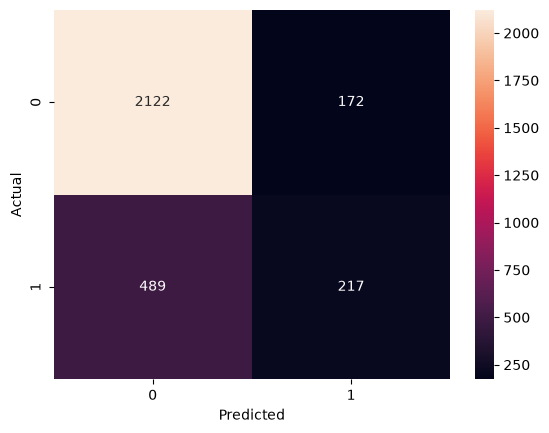

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt 

sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [21]:
from sklearn.tree import DecisionTreeClassifier
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
trees_pred = tree_model.predict(X_test)

In [22]:
from sklearn.metrics import accuracy_score
tree_pred = tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)
print("Decision Tree Accuracy", tree_accuracy)

Decision Tree Accuracy 0.9763333333333334


In [23]:
from sklearn.metrics import classification_report
print(classification_report(y_test, tree_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      2294
           1       0.94      0.96      0.95       706

    accuracy                           0.98      3000
   macro avg       0.96      0.97      0.97      3000
weighted avg       0.98      0.98      0.98      3000



In [24]:
import pandas as pd 
importance = pd.Series(
  tree_model.feature_importances_,
  index=X_train.columns
)
print(importance.sort_values(ascending=False).head(10))

satisfaction_level      0.502314
last_evaluation         0.150563
time_spend_company      0.137813
number_project          0.098448
average_montly_hours    0.088621
Department_technical    0.003831
salary_medium           0.003502
Department_support      0.002862
salary_low              0.002667
salary_high             0.002153
dtype: float64
